# Notebook 10a - Huis Generation
---

### 1. Imports
---

In [ ]:
import sys
from pathlib import Path
import itertools
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX


import warnings
warnings.filterwarnings("ignore")

runtimes = {}

### 2. Bestanden
---

In [ ]:
#Projectmap zoeken, werkt vanuit elke submap van models/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "prepared_data").exists())

sys.path.insert(0, str(ROOT))
from exploration.open_meteo_weer_merge import haal_modeldata_op

RESULTS_DIR = ROOT / "models" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

SPLIT_FILE = ROOT / "prepared_data" / "model_split.parquet"

LOCATION = "huis"
TARGET_TYPE = "generation"

### 3. Modelinstellingen
---

In [ ]:
EXOG_FEATURES = ["temperature_2m","shortwave_radiation","relative_humidity_2m"]

m = 24 #(dag)
D = 1

#Horizons op 1, 6, 12, 24, 48 en 72 uur en ieder uur nieuw forecastmoment
HORIZONS = [1, 6, 12, 24, 48, 72]
ORIGIN_STAP_UREN = 1

### 4. Data en split inladen
---

In [ ]:
data = haal_modeldata_op()
split = pd.read_parquet(SPLIT_FILE).iloc[0]

### 5. Target selectie
---

In [ ]:
deel = data[
    (data["location"] == LOCATION) &
    (data["target_type"] == TARGET_TYPE) &
    (data["timestamp_nl"] >= split["train_start"]) &
    (data["timestamp_nl"] < split["test_end"])
].copy()

deel = deel.sort_values("timestamp_nl").reset_index(drop=True)

### 6. Uurgemiddelde maken van 5 minutendata
---
- `pow_imputed` wordt `y_model`, hoofdtarget voor training+evaluatie
- `pow_w` wordt `y_echt`, 'optionele' controle later
- Uurdata omdat m = 24 eenvoudiger is dan m = 288 (24 * 12 (12 5 minuten-metingen per uur))

In [ ]:
#Timestamp als index zetten
deel = deel.set_index("timestamp_nl")

#Omzetten naar uurgemiddelde
uurdata = deel.resample("1h").agg(
    y_model=("pow_imputed", "mean"),
    y_echt=("pow_w", "mean"),
    Temperatuur=("temperature_2m", "mean"),
    GlobaleStraling=("shortwave_radiation", "mean"),
    luchtvochtigheid=("relative_humidity_2m", "mean")
)

uurdata.head()

,y_model,y_echt,Temperatuur,GlobaleStraling,DuurNeerslag
timestamp,,,,,
2025-10-21 22:00:00+02:00,-0.005189,0.0,12.4,0.0,0.0
2025-10-21 23:00:00+02:00,0.000000,0.0,12.3,0.0,0.0
2025-10-22 00:00:00+02:00,0.000000,0.0,11.6,0.0,0.0
2025-10-22 01:00:00+02:00,0.000000,0.0,12.0,0.0,0.0
2025-10-22 02:00:00+02:00,0.000000,0.0,12.3,0.0,0.0


In [7]:
missend_weer = uurdata[EXOG_FEATURES].isna().sum()
missend_weer

Temperatuur        0
GlobaleStraling    0
DuurNeerslag       0
dtype: int64

### 7. Train/Val/Test split laden
---
- `Train-Test-Val--Split.ipynb`
- 0.7/0.15/0.15
- Zelfde split over elk vd 4 notebooks

In [8]:
train = uurdata[(uurdata.index >= split["train_start"]) & (uurdata.index < split["train_end"])].copy()
validation = uurdata[(uurdata.index >= split["val_start"]) & (uurdata.index < split["val_end"])].copy()
test = uurdata[(uurdata.index >= split["test_start"]) & (uurdata.index < split["test_end"])].copy()

In [9]:
print("Train:", len(train), "uur")
print("Validation:", len(validation), "uur")
print("Test:", len(test), "uur")

Train: 2917 uur
Validation: 625 uur
Test: 624 uur


### 8. Stationariteit (ADF)
---
- `y_model`
- p waarde kleiner dan 0.05 dan d = 0 anders d = 1


In [10]:
pow_uur = train["y_model"].dropna()
seizoensverschil = pow_uur.diff(m).dropna()

ADF = adfuller(seizoensverschil, autolag="AIC")
d = 0 if ADF[1] < 0.05 else 1

In [11]:
print("ADF:", ADF[0])
print("p-value:", ADF[1])
print("d:", d)
print("D:", D)
print("m:", m)

ADF: -14.160965878573535
p-value: 2.0813784235212448e-26
d: 0
D: 1
m: 24


### 9. ACF en PACF
---
- ACF over 8 dagen om zo weekpatroon ook te laten zien
- (Dag)patroon pieken rond iedere 24 uur 

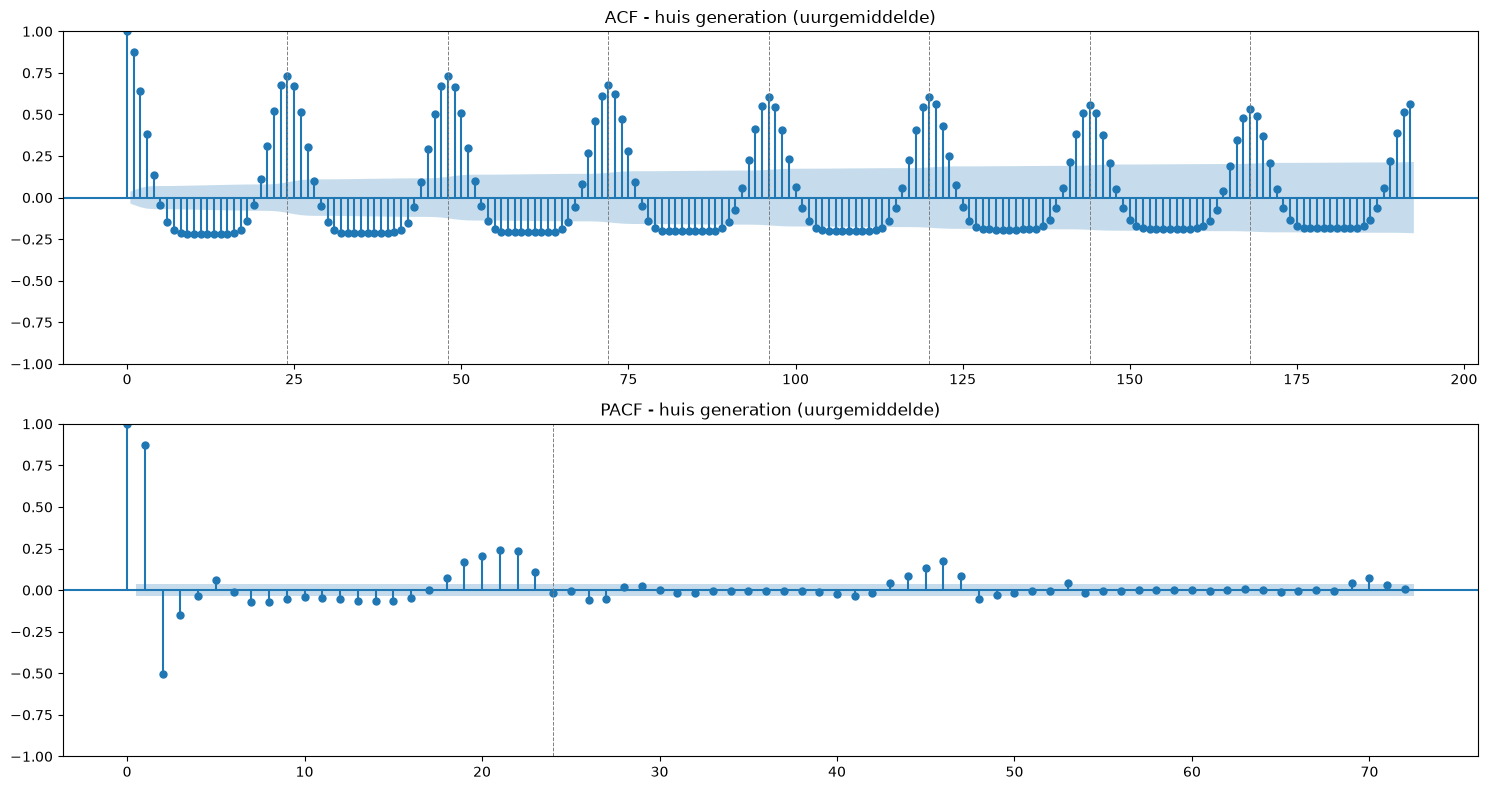

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(15, 8))

plot_acf(pow_uur, lags=24 * 8, ax=axes[0])
axes[0].set_title(f"ACF - {LOCATION} {TARGET_TYPE} (uurgemiddelde)")

for dag in range(1, 8):
    axes[0].axvline(24 * dag, color="grey", linestyle="--", linewidth=0.7)

plot_pacf(pow_uur, lags=24 * 3, ax=axes[1], method="ywm")
axes[1].set_title(f"PACF - {LOCATION} {TARGET_TYPE} (uurgemiddelde)")
axes[1].axvline(24, color="grey", linestyle="--", linewidth=0.7)

plt.tight_layout()
plt.show()

### 10. ARIMA
---


### 10.1 Grid
---
- Combinaties p en q proberen, d is al bekend uit ADF
- Lagere AIC steunt betere model fitting

In [13]:
resultaten_arima = []

for p, q in itertools.product(range(0, 5), range(0, 5)):
    try:
        model = ARIMA(
            train["y_model"],
            order=(p, d, q)
        ).fit()

        resultaten_arima.append({
            "p": p,
            "d": d,
            "q": q,
            "AIC": model.aic
        })

        print(f"ARIMA({p},{d},{q})  AIC={model.aic:.1f}")

    except Exception as e:
        print(f"ARIMA({p},{d},{q}) mislukt: {e}")

ARIMA(0,0,0)  AIC=38853.1
ARIMA(0,0,1)  AIC=36156.7
ARIMA(0,0,2)  AIC=34908.6
ARIMA(0,0,3)  AIC=34250.5
ARIMA(0,0,4)  AIC=33911.1
ARIMA(1,0,0)  AIC=34654.9
ARIMA(1,0,1)  AIC=34097.2
ARIMA(1,0,2)  AIC=33940.9
ARIMA(1,0,3)  AIC=33809.4
ARIMA(1,0,4)  AIC=33765.7
ARIMA(2,0,0)  AIC=33809.6
ARIMA(2,0,1)  AIC=33744.0
ARIMA(2,0,2)  AIC=33741.3
ARIMA(2,0,3)  AIC=33729.3
ARIMA(2,0,4)  AIC=33710.8
ARIMA(3,0,0)  AIC=33743.2
ARIMA(3,0,1)  AIC=33743.2
ARIMA(3,0,2)  AIC=33747.7
ARIMA(3,0,3)  AIC=33730.6
ARIMA(3,0,4)  AIC=33733.3
ARIMA(4,0,0)  AIC=33741.6
ARIMA(4,0,1)  AIC=33738.4
ARIMA(4,0,2)  AIC=33727.2
ARIMA(4,0,3)  AIC=33729.2
ARIMA(4,0,4)  AIC=33733.1


### 10.2 Beste order
---

In [14]:
grid_arima = pd.DataFrame(resultaten_arima).sort_values("AIC").reset_index(drop=True)
grid_arima.head(10)

,p,d,q,AIC
0,2,0,4,33710.794786
1,4,0,2,33727.248254
2,4,0,3,33729.215393
3,2,0,3,33729.302972
4,3,0,3,33730.570127
5,4,0,4,33733.077062
6,3,0,4,33733.293401
7,4,0,1,33738.398807
8,2,0,2,33741.257071
9,4,0,0,33741.627147


In [15]:
p_arima = int(grid_arima.loc[0, "p"])
q_arima = int(grid_arima.loc[0, "q"])

arima_order = (p_arima, d, q_arima)

print("Beste ARIMA-order:", arima_order)
print("AIC:", round(grid_arima.loc[0, "AIC"], 1))

Beste ARIMA-order: (2, 0, 4)
AIC: 33710.8


### 10.3 Beste model fitten
---

In [16]:
arima_best = ARIMA(train["y_model"],order=arima_order).fit()
print(arima_best.summary())

                               SARIMAX Results                                
Dep. Variable:                y_model   No. Observations:                 2917
Model:                 ARIMA(2, 0, 4)   Log Likelihood              -16847.397
Date:                Mon, 19 Oct 2026   AIC                          33710.795
Time:                        17:06:36   BIC                          33758.621
Sample:                    10-21-2025   HQIC                         33728.022
                         - 02-20-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -88.0842     10.506     -8.384      0.000    -108.675     -67.493
ar.L1          1.5977      0.053     30.303      0.000       1.494       1.701
ar.L2         -0.6988      0.029    -23.785      0.0

### 11. SARIMA
---
- ARIMA met seasonal component

### 11.1 Parameters
---
- p, q, P en Q variatie

In [17]:
sarima_parameters = list(itertools.product(
    range(0, 2),
    range(0, 2),
    range(0, 2),
    range(0, 2)
))

print("Aantal SARIMA-combinaties:", len(sarima_parameters))

Aantal SARIMA-combinaties: 16


### 11.2 Grid
---

In [18]:
t0 = time.perf_counter()
resultaten_sarima = []

for p, q, P, Q in sarima_parameters:
    try:
        model = SARIMAX(
            train["y_model"],
            order=(p, d, q),
            seasonal_order=(P, D, Q, m),
            enforce_stationarity=False,
            enforce_invertibility=False
        ).fit(disp=False)

        resultaten_sarima.append({
            "p": p,
            "d": d,
            "q": q,
            "P": P,
            "D": D,
            "Q": Q,
            "m": m,
            "AIC": model.aic
        })

        print(f"SARIMA({p},{d},{q})({P},{D},{Q},{m})  AIC={model.aic:.1f}")

    except Exception as e:
        print(f"SARIMA({p},{d},{q})({P},{D},{Q},{m}) mislukt: {e}")
runtimes["gridsearch SARIMA"] = time.perf_counter() - t0

SARIMA(0,0,0)(0,1,0,24)  AIC=36625.0
SARIMA(0,0,0)(0,1,1,24)  AIC=35027.8
SARIMA(0,0,0)(1,1,0,24)  AIC=35389.9
SARIMA(0,0,0)(1,1,1,24)  AIC=35024.9
SARIMA(0,0,1)(0,1,0,24)  AIC=34970.3
SARIMA(0,0,1)(0,1,1,24)  AIC=33176.9
SARIMA(0,0,1)(1,1,0,24)  AIC=33748.9
SARIMA(0,0,1)(1,1,1,24)  AIC=33178.6
SARIMA(1,0,0)(0,1,0,24)  AIC=34403.6
SARIMA(1,0,0)(0,1,1,24)  AIC=32339.8
SARIMA(1,0,0)(1,1,0,24)  AIC=33085.9
SARIMA(1,0,0)(1,1,1,24)  AIC=32341.0
SARIMA(1,0,1)(0,1,0,24)  AIC=34324.5
SARIMA(1,0,1)(0,1,1,24)  AIC=32238.3
SARIMA(1,0,1)(1,1,0,24)  AIC=33034.4
SARIMA(1,0,1)(1,1,1,24)  AIC=32239.6


### 11.3 Beste order
---

In [19]:
grid_sarima = pd.DataFrame(resultaten_sarima).sort_values("AIC").reset_index(drop=True)
grid_sarima.head(10)

,p,d,q,P,D,Q,m,AIC
0,1,0,1,0,1,1,24,32238.327194
1,1,0,1,1,1,1,24,32239.593891
2,1,0,0,0,1,1,24,32339.766220
3,1,0,0,1,1,1,24,32341.042358
4,1,0,1,1,1,0,24,33034.440808
5,1,0,0,1,1,0,24,33085.912051
6,0,0,1,0,1,1,24,33176.857531
7,0,0,1,1,1,1,24,33178.647503
8,0,0,1,1,1,0,24,33748.930009
9,1,0,1,0,1,0,24,34324.485497


In [20]:
r = grid_sarima.iloc[0]

p = int(r["p"])
q = int(r["q"])
P = int(r["P"])
Q = int(r["Q"])

order = (p, d, q)
seasonal_order = (P, D, Q, m)

print("Beste SARIMA-order:", order, seasonal_order)
print("AIC:", round(r["AIC"], 1))

Beste SARIMA-order: (1, 0, 1) (0, 1, 1, 24)
AIC: 32238.3


### 11.4 Beste model fitten

In [21]:
t0 = time.perf_counter()
sarima_best = SARIMAX(
    train["y_model"],
    order=order,
    seasonal_order=seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)
runtimes["training SARIMA"] = time.perf_counter() - t0
print(f"training SARIMA: {runtimes['training SARIMA']:.1f}s")

print(sarima_best.summary())

training SARIMA: 8.9s
                                     SARIMAX Results                                      
Dep. Variable:                            y_model   No. Observations:                 2917
Model:             SARIMAX(1, 0, 1)x(0, 1, 1, 24)   Log Likelihood              -16115.164
Date:                            Mon, 19 Oct 2026   AIC                          32238.327
Time:                                    17:07:58   BIC                          32262.171
Sample:                                10-21-2025   HQIC                         32246.924
                                     - 02-20-2026                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.7125      0.007     96.139      0.000       0.698       0.727
ma.L1        

### 11.5 Diagnostics
---
- Verdeling van residuen
- Autocorrelatie

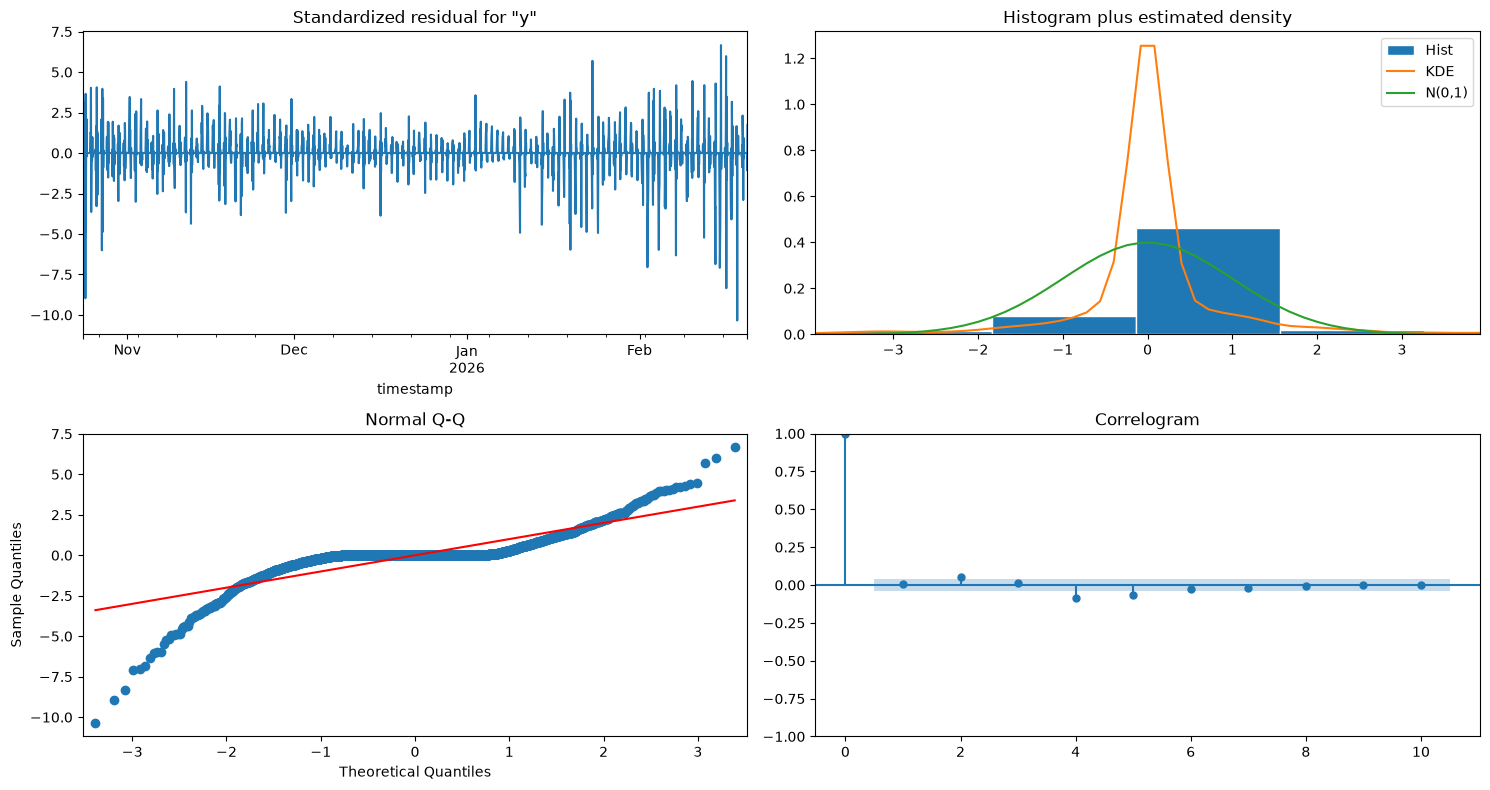

In [22]:
sarima_best.plot_diagnostics(figsize=(15, 8))
plt.tight_layout()
plt.show()

### 11.6 Ljung Box Test
---

In [23]:
residuen_sarima = pd.Series(
    sarima_best.resid,
    index=train.index
).dropna()

ljung_sarima = acorr_ljungbox(
    residuen_sarima,
    lags=[24, 48],
    return_df=True
)

ljung_sarima

,lb_stat,lb_pvalue
24,87.182070,4.197719e-09
48,167.752483,3.473997e-15


### 12. SARIMAX met weerdata
---
- Exogene (externe) variabelen toevoegen aan SARIMA
- `Temperatuur`, `GlobaleStraling`, `DuurNeerslag`

### 12.1 Scaling
---
- Weerfeatures standaardiseren met gemiddelde en std van train

In [24]:
exog_mean = train[EXOG_FEATURES].mean()
exog_std = train[EXOG_FEATURES].std()

exog_scaled = (uurdata[EXOG_FEATURES] - exog_mean) / exog_std

pd.DataFrame({"train_mean": exog_mean, "train_std": exog_std})

,train_mean,train_std
Temperatuur,4.782928,4.760991
GlobaleStraling,12.142269,24.052440
DuurNeerslag,0.889955,2.493041


### 12.2 Fitten
---
- Verschil tov SARIMA is alleen de toevoeging van weerdata
- p.s. later hoogstwaarschijnlijk weerdata meteo gebruiken ipv KNMI

In [25]:
t0 = time.perf_counter()
sarimax_best = SARIMAX(
    train["y_model"],
    exog=exog_scaled.loc[train.index],
    order=order,
    seasonal_order=seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)
runtimes["training SARIMAX"] = time.perf_counter() - t0
print(f"training SARIMAX: {runtimes['training SARIMAX']:.1f}s")

training SARIMAX: 29.0s


### 12.3 SARIMA VS SARIMAX
---

In [26]:
print("SARIMA AIC :", round(sarima_best.aic, 1))
print("SARIMAX AIC:", round(sarimax_best.aic, 1))

SARIMA AIC : 32238.3
SARIMAX AIC: 31332.2


In [27]:
print(sarimax_best.summary())

                                     SARIMAX Results                                      
Dep. Variable:                            y_model   No. Observations:                 2917
Model:             SARIMAX(1, 0, 1)x(0, 1, 1, 24)   Log Likelihood              -15659.081
Date:                            Mon, 19 Oct 2026   AIC                          31332.161
Time:                                    17:08:27   BIC                          31373.888
Sample:                                10-21-2025   HQIC                         31347.205
                                     - 02-20-2026                                         
Covariance Type:                              opg                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Temperatuur        -8.5219      4.677     -1.822      0.068     -17.689       0.645
GlobaleStraling  -10

### 12.4 Diagnostics
---

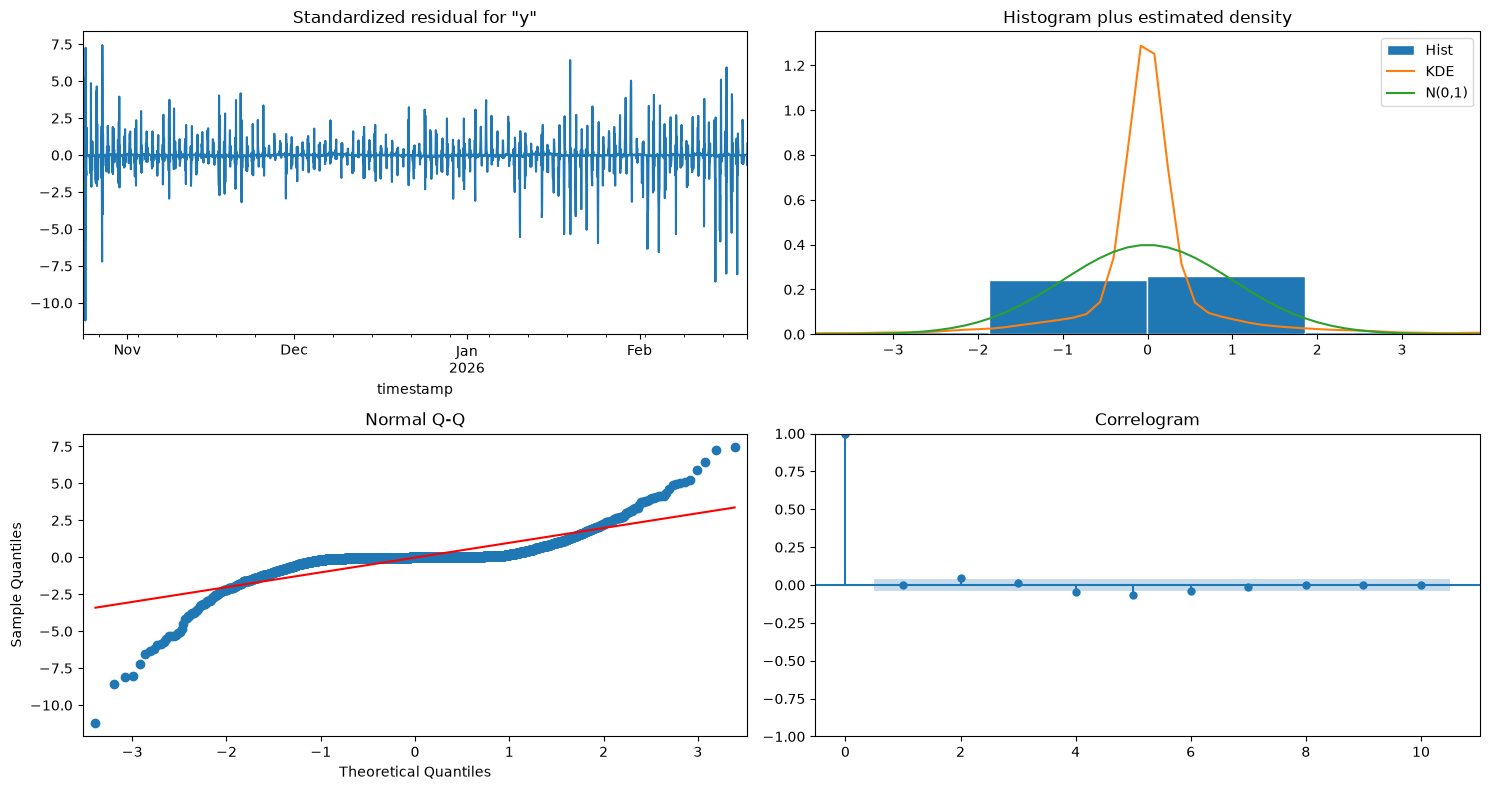

In [28]:
sarimax_best.plot_diagnostics(figsize=(15, 8))
plt.tight_layout()
plt.show()

In [29]:
residuen_sarimax = pd.Series(
    sarimax_best.resid,
    index=train.index
).dropna()

ljung_sarimax = acorr_ljungbox(
    residuen_sarimax,
    lags=[24, 48],
    return_df=True
)

print("SARIMA:")
display(ljung_sarima)

print("SARIMAX:")
display(ljung_sarimax)

SARIMA:


,lb_stat,lb_pvalue
24,87.182070,4.197719e-09
48,167.752483,3.473997e-15


SARIMAX:


,lb_stat,lb_pvalue
24,50.239814,1.319779e-03
48,189.941604,8.817769e-19


### 13. Forecasting baselines
---
- Laatste waarde en seasonal naive (laatste 24 u) ter vergelijking

In [30]:
def seasonal_naive(history, stappen):
    laatste_dag = history.dropna().iloc[-24:].to_numpy()
    voorspelling = []

    for stap in range(stappen):
        positie = stap % 24
        voorspelling.append(laatste_dag[positie])

    return np.array(voorspelling)

### 14. Rolling Forecast
---

In [31]:
def rolling_forecast(
    uurdata,
    exog_scaled,
    sarima_fit,
    sarimax_fit
):
    resultaten = []
    max_horizon = max(HORIZONS)

    huidig_sarima = sarima_fit
    huidig_sarimax = sarimax_fit
    huidig_einde = train.index.max()

    #Laatste bekende uur voor test
    eerste_origin = uurdata[uurdata.index < test.index.min()].index.max()
    validation_nieuw = uurdata[(uurdata.index > huidig_einde) & (uurdata.index <= eerste_origin)]

    if len(validation_nieuw) > 0:
        #Nieuwe waarnemingen toevoegen zonder opnieuw te fitten
        huidig_sarima = huidig_sarima.extend(validation_nieuw["y_model"])
        huidig_sarimax = huidig_sarimax.extend(validation_nieuw["y_model"], exog=exog_scaled.loc[validation_nieuw.index])
        huidig_einde = eerste_origin

    laatste_origin = (test.index.max() - pd.Timedelta(hours=max_horizon))

    origins = pd.date_range(eerste_origin, laatste_origin, freq=f"{ORIGIN_STAP_UREN}h")

    for origin in origins:
        nieuwe_data = uurdata[(uurdata.index > huidig_einde) & (uurdata.index <= origin)]

        if len(nieuwe_data) > 0:
            #Nieuwe waarneming toevoegen
            huidig_sarima = huidig_sarima.extend(nieuwe_data["y_model"])

            huidig_sarimax = huidig_sarimax.extend(nieuwe_data["y_model"], exog=exog_scaled.loc[nieuwe_data.index])

            huidig_einde = origin

        toekomstige_index = pd.date_range(origin + pd.Timedelta(hours=1), periods=max_horizon, freq="1h")

        #Alleen voorspellen als de volledige horizon in de data ligt
        if not toekomstige_index.isin(uurdata.index).all(): continue

        forecast_sarima = huidig_sarima.get_forecast(steps=max_horizon).predicted_mean

        forecast_sarimax = huidig_sarimax.get_forecast(steps=max_horizon, exog=exog_scaled.loc[toekomstige_index]).predicted_mean

        history = uurdata.loc[:origin, "y_model"]

        last_value = history.dropna().iloc[-1]

        forecast_last = np.repeat(last_value, max_horizon)

        forecast_seasonal = seasonal_naive(history, max_horizon)

        for stap in range(1, max_horizon + 1):
            valid_time = origin + pd.Timedelta(hours=stap)

            resultaten.append({
                "origin": origin,
                "valid_time": valid_time,
                "horizon_h": stap,
                "actual": uurdata.loc[valid_time, "y_model"],
                "actual_echt": uurdata.loc[valid_time, "y_echt"],
                "last": forecast_last[stap - 1],
                "seasonal_naive": forecast_seasonal[stap - 1],
                "SARIMA": forecast_sarima.iloc[stap - 1],
                "SARIMAX": forecast_sarimax.iloc[stap - 1]
            })

    return pd.DataFrame(resultaten)

In [32]:
t0 = time.perf_counter()
voorspellingen = rolling_forecast(
    uurdata,
    exog_scaled,
    sarima_best,
    sarimax_best
)
runtimes["rolling forecast"] = time.perf_counter() - t0
print(f"rolling forecast: {runtimes['rolling forecast']:.1f}s")

rolling forecast: 16.2s


### 15. Evaluatie
---

In [33]:
def bereken_scores(voorspellingen, werkelijk_kolom):
    modellen = ["last", "seasonal_naive", "SARIMA", "SARIMAX"]
    resultaten = []

    for horizon in HORIZONS:
        deel_horizon = voorspellingen[voorspellingen["horizon_h"] == horizon]

        for model in modellen:
            geldig = deel_horizon[[werkelijk_kolom, model]].dropna()

            if len(geldig) == 0: continue

            y_true = geldig[werkelijk_kolom]
            y_pred = geldig[model]

            mae = mean_absolute_error(y_true, y_pred)
            rmse = root_mean_squared_error(y_true, y_pred)

            noemer = np.abs(y_true).sum()
            if noemer > 0: wape = np.abs(y_true - y_pred).sum() / noemer * 100
            else: wape = np.nan

            resultaten.append({
                "horizon_h": horizon,
                "model": model,
                "n": len(geldig),
                "MAE_W": mae,
                "RMSE_W": rmse,
                "WAPE_pct": wape
            })

    return pd.DataFrame(resultaten)

### Evaluatie
---
- Op `pow_imputed`

In [34]:
scores = bereken_scores(
    voorspellingen,
    "actual"
)

scores.round(2)

,horizon_h,model,n,MAE_W,RMSE_W,WAPE_pct
0,1,last,553,174.49,293.15,32.14
1,1,seasonal_naive,553,249.98,494.00,46.05
2,1,SARIMA,553,108.65,191.27,20.02
3,1,SARIMAX,553,94.79,174.50,17.46
4,6,last,553,812.43,1125.07,151.90
5,6,seasonal_naive,553,237.99,466.82,44.50
6,6,SARIMA,553,211.08,353.36,39.46
7,6,SARIMAX,553,144.30,242.67,26.98
8,12,last,553,1072.34,1309.54,201.09
9,12,seasonal_naive,553,237.03,466.13,44.45


In [35]:
scores.pivot(
    index="horizon_h",
    columns="model",
    values="MAE_W"
).round(1)

model,SARIMA,SARIMAX,last,seasonal_naive
horizon_h,,,,
1,108.7,94.8,174.5,250.0
6,211.1,144.3,812.4,238.0
12,203.8,139.8,1072.3,237.0
24,199.2,139.4,239.7,239.7
48,195.8,138.4,251.3,251.3
72,188.6,135.0,254.9,254.9


### Evaluatie
---
- Op oorspronkelijke `pow_w` metingen

In [36]:
scores_echt = bereken_scores(
    voorspellingen,
    "actual_echt"
)

scores_echt.round(2)

,horizon_h,model,n,MAE_W,RMSE_W,WAPE_pct
0,1,last,553,174.12,292.51,32.06
1,1,seasonal_naive,553,250.21,493.73,46.07
2,1,SARIMA,553,108.26,190.76,19.93
3,1,SARIMAX,553,94.58,173.67,17.41
4,6,last,550,814.36,1127.67,152.98
5,6,seasonal_naive,550,237.79,467.12,44.67
6,6,SARIMA,550,211.94,354.01,39.82
7,6,SARIMAX,550,143.42,242.15,26.94
8,12,last,544,1079.00,1316.88,201.64
9,12,seasonal_naive,544,238.83,468.92,44.63


In [37]:
scores_echt.pivot(
    index="horizon_h",
    columns="model",
    values="MAE_W"
).round(1)

model,SARIMA,SARIMAX,last,seasonal_naive
horizon_h,,,,
1,108.3,94.6,174.1,250.2
6,211.9,143.4,814.4,237.8
12,206.3,139.9,1079.0,238.8
24,203.8,141.4,243.9,243.9
48,200.3,140.6,255.2,255.2
72,192.8,137.1,256.4,256.4


### 16. Visualisaties
---

In [38]:
origin = voorspellingen["origin"].min()
plotdata = voorspellingen[voorspellingen["origin"] == origin].copy()
historie = uurdata.loc[origin - pd.Timedelta(days=3) : origin, "y_model"]

### Voorbeeld één forecast komende 72 uur
---

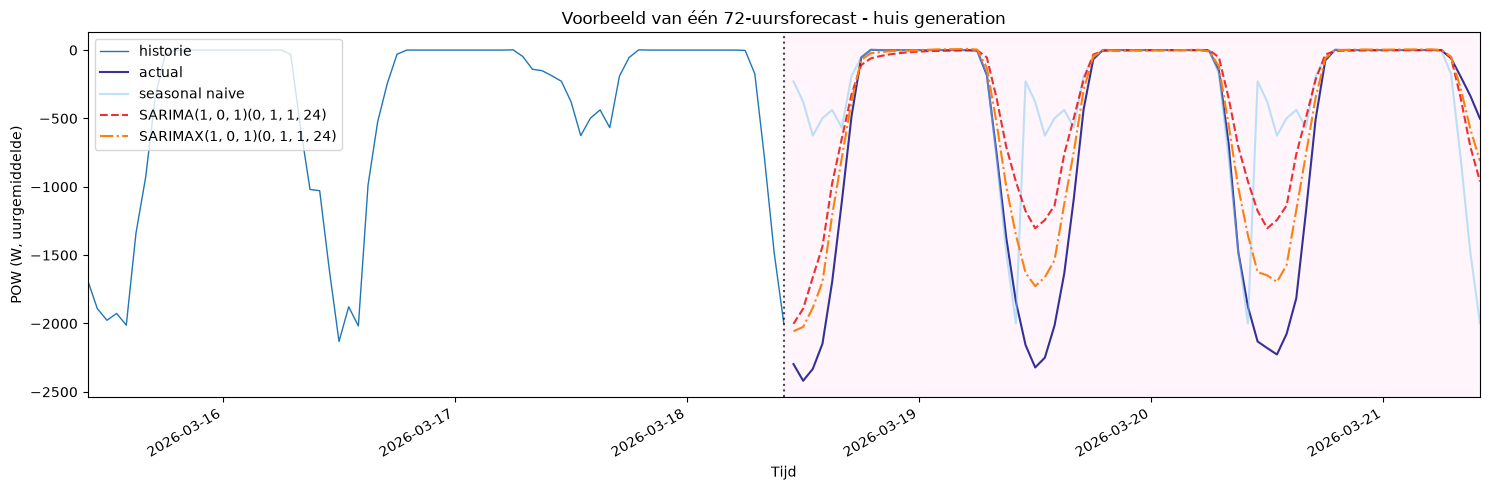

In [39]:
fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(historie,linewidth=1,label="historie")

#Werkelijke waarden
ax.plot(plotdata["valid_time"], plotdata["actual"], color="#000080", linestyle="-", label="actual", alpha=0.8)

#Seasonal naive
ax.plot(plotdata["valid_time"], plotdata["seasonal_naive"], color="#7BC8F6", linestyle="-", label="seasonal naive", alpha=0.5)

#SARIMA
ax.plot(plotdata["valid_time"], plotdata["SARIMA"], color="#E50000", linestyle="--", label=f"SARIMA{order}{seasonal_order}", alpha=0.8)

#SARIMAX
ax.plot(plotdata["valid_time"], plotdata["SARIMAX"], color="#FF7F0E", linestyle="-.", label=f"SARIMAX{order}{seasonal_order}")

ax.axvspan(origin, origin + pd.Timedelta(hours=72), color="#FFCDEA", alpha=0.2)

ax.axvline(origin,color="black",linestyle=":",alpha=0.7)

ax.set_xlim(origin - pd.Timedelta(days=3), origin + pd.Timedelta(hours=72))

ax.legend(loc=2)
ax.set_xlabel("Tijd")
ax.set_ylabel("POW (W, uurgemiddelde)")
ax.set_title(f"Voorbeeld van één 72-uursforecast - {LOCATION} {TARGET_TYPE}")

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### Gemiddelde absolute fout per horizon
---

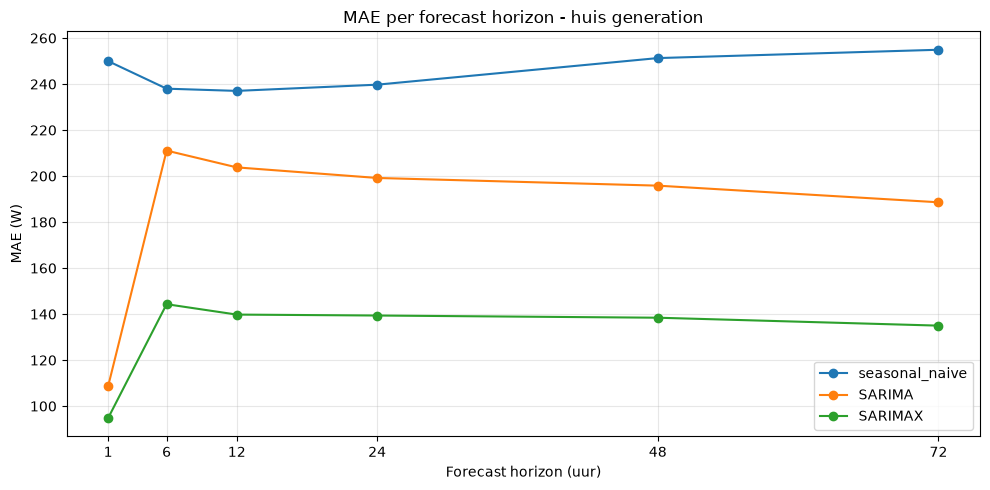

In [40]:
fig, ax = plt.subplots(figsize=(10, 5))

for model in ["seasonal_naive", "SARIMA", "SARIMAX"]:
    deel = scores[scores["model"] == model]
    ax.plot(deel["horizon_h"], deel["MAE_W"], marker="o", label=model)

ax.set_xticks(HORIZONS)

ax.set_xlabel("Forecast horizon (uur)")
ax.set_ylabel("MAE (W)")
ax.set_title(f"MAE per forecast horizon - {LOCATION} {TARGET_TYPE}")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Rolling forecast op 72 uur tijd
---
- Elk voorspeld punt is 72 uur van tevoren gemaakt

In [41]:
plot_72 = voorspellingen[voorspellingen["horizon_h"] == 72].copy()

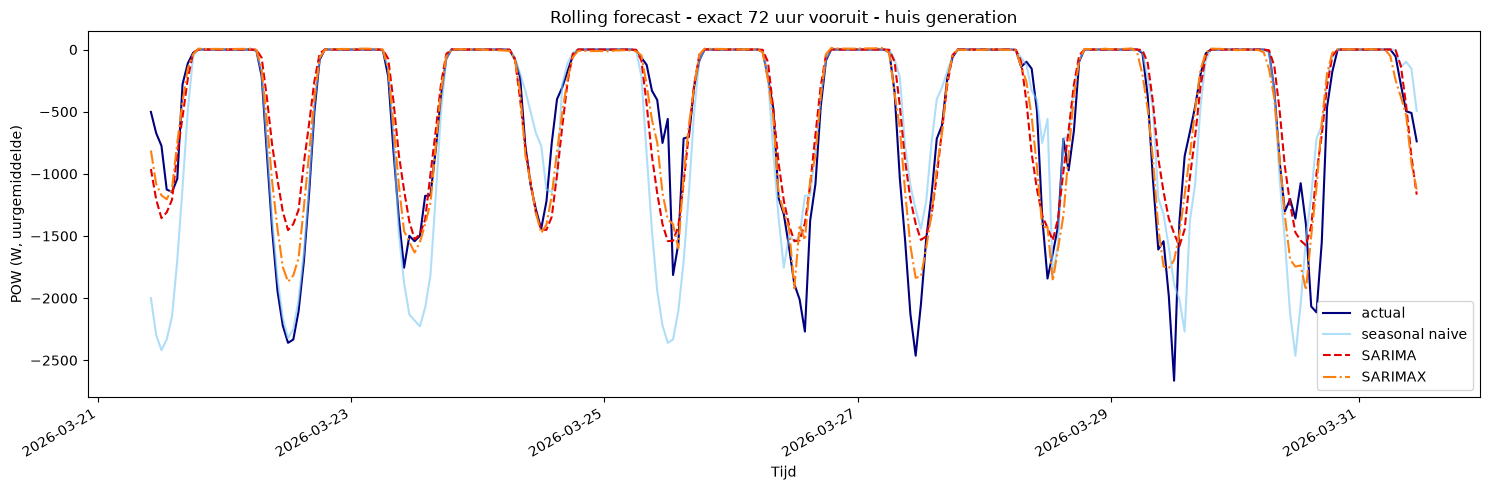

In [42]:
start_plot = plot_72["valid_time"].min()
einde_plot = start_plot + pd.Timedelta(days=10)

plot_72 = plot_72[(plot_72["valid_time"] >= start_plot) & (plot_72["valid_time"] <= einde_plot)]

fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(plot_72["valid_time"], plot_72["actual"] ,color="#000080" ,label="actual")

ax.plot(plot_72["valid_time"], plot_72["seasonal_naive"], color="#7BC8F6", label="seasonal naive", alpha=0.6)

ax.plot(plot_72["valid_time"], plot_72["SARIMA"], color="#E50000", linestyle="--", label="SARIMA")

ax.plot(plot_72["valid_time"], plot_72["SARIMAX"], color="#FF7F0E",linestyle="-.", label="SARIMAX")

ax.set_xlabel("Tijd")
ax.set_ylabel("POW (W, uurgemiddelde)")
ax.set_title(f"Rolling forecast - exact 72 uur vooruit - {LOCATION} {TARGET_TYPE}")

ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### 17. Eindevaluatie
---
- Stationaire reeks na differencing
- ARIMA order (2, 0, 4) met AIC van 33710.8
- SARIMA order (1, 0, 1)(0, 1, 1, 24), AIC daalt naar 32238.3
- Weerfeatures toevoeging zorgt ervoor dat AIC daalt naar 31332.2, dus deze zijn van prima waarde, GlobaleStraling erg statistisch significant
- SARIMAX heeft een gemiddelde absolute fout van 135 W op 72 uur vooruit tegenover de 188.6 W van SARIMA

### 18. Resultaten opslaan
---
- Zelfde format als de andere modellen, opgeslagen in `models/results/`
- MAE en RMSE over alle horizons (1 t/m 72 uur) op `pow_imputed`
- MAE dag 1/2/3 = horizon 1-24, 25-48 en 49-72 uur
- Rolling = één forecast per dag (elke 24e origin)
- Voorspeltijd is de rolling forecast voor SARIMA en SARIMAX samen
- Let op: andere testperiode en resolutie (uur) dan de 5-minutenmodellen

In [43]:
modelnamen = {"SARIMA": "SARIMA", "SARIMAX": "SARIMAX", "seasonal_naive": "Seasonal naive (24u)", "last": "Laatste waarde"}

origins = np.sort(voorspellingen["origin"].unique())
dagelijkse_origins = origins[::24]

rijen = {}
for kolom, naam in modelnamen.items():
    fout = voorspellingen[kolom] - voorspellingen["actual"]
    res = {"MAE": fout.abs().mean(), "RMSE": np.sqrt((fout ** 2).mean())}
    for dag in range(3):
        deel = voorspellingen["horizon_h"].between(dag * 24 + 1, (dag + 1) * 24)
        res[f"MAE dag {dag + 1}"] = fout[deel].abs().mean()
    #Rolling: per dagelijkse forecast de MAE/RMSE, daarna gemiddeld
    dagelijks = voorspellingen["origin"].isin(dagelijkse_origins)
    per_venster = fout[dagelijks].groupby(voorspellingen.loc[dagelijks, "origin"])
    res["rolling MAE"] = per_venster.apply(lambda x: x.abs().mean()).mean()
    res["rolling RMSE"] = per_venster.apply(lambda x: np.sqrt((x ** 2).mean())).mean()
    rijen[naam] = res

resultaten = pd.DataFrame(rijen).T
resultaten.loc["SARIMA", "trainingstijd (s)"] = runtimes["training SARIMA"]
resultaten.loc["SARIMAX", "trainingstijd (s)"] = runtimes["training SARIMAX"]
resultaten.loc[["SARIMA", "SARIMAX"], "voorspeltijd (s)"] = runtimes["rolling forecast"]
resultaten = resultaten.round(1)

#Model opslaan en bestandsgrootte meten
MODEL_DIR = ROOT / "models" / "saved_models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

def grootte_mb(pad):
    pad = Path(pad)
    if pad.is_dir():
        return sum(f.stat().st_size for f in pad.rglob("*") if f.is_file()) / 1e6
    return pad.stat().st_size / 1e6

import copy

#remove_data=True: alleen het model opslaan, niet de trainingsdata
for naam, fit in [("SARIMA", sarima_best), ("SARIMAX", sarimax_best)]:
    pad = MODEL_DIR / f"10a_{naam.lower()}_{LOCATION}_{TARGET_TYPE}.pkl"
    copy.deepcopy(fit).save(pad, remove_data=True)
    resultaten.loc[naam, "modelgrootte (MB)"] = grootte_mb(pad)
resultaten["modelgrootte (MB)"] = resultaten["modelgrootte (MB)"].round(3)

KOLOMMEN = ["notebook", "locatie", "target", "resolutie", "testperiode", "MAE", "RMSE", "MAE dag 1", "MAE dag 2",
            "MAE dag 3", "rolling MAE", "rolling RMSE", "trainingstijd (s)", "voorspeltijd (s)",
            "modelgrootte (MB)"]
resultaten["notebook"] = "10a_Huis_Generation_SARIMAX"
resultaten["locatie"] = LOCATION
resultaten["target"] = TARGET_TYPE
resultaten["resolutie"] = "1 uur"
resultaten["testperiode"] = f"{test.index.min():%Y-%m-%d} t/m {test.index.max():%Y-%m-%d}"
resultaten = resultaten.reindex(columns=KOLOMMEN)
resultaten.to_csv(RESULTS_DIR / f"10a_sarimax_{LOCATION}_{TARGET_TYPE}.csv")
resultaten

,notebook,locatie,target,resolutie,testperiode,MAE,RMSE,MAE dag 1,MAE dag 2,MAE dag 3,rolling MAE,rolling RMSE,trainingstijd (s),voorspeltijd (s),modelgrootte (MB)
SARIMA,10a_Huis_Generation_SARIMAX,huis,generation,1 uur,2026-03-18 t/m 2026-04-13,194.1,347.4,197.3,195.3,189.8,188.7,329.1,8.9,16.2,180.091
SARIMAX,10a_Huis_Generation_SARIMAX,huis,generation,1 uur,2026-03-18 t/m 2026-04-13,137.2,239.6,138.1,138.0,135.6,134.1,230.1,29.0,16.2,180.255
Seasonal naive (24u),10a_Huis_Generation_SARIMAX,huis,generation,1 uur,2026-03-18 t/m 2026-04-13,248.6,470.2,239.0,247.8,259.0,256.0,475.3,NaN,NaN,NaN
Laatste waarde,10a_Huis_Generation_SARIMAX,huis,generation,1 uur,2026-03-18 t/m 2026-04-13,744.5,1056.2,737.8,745.9,749.8,1110.1,1226.0,NaN,NaN,NaN
